# Bayesian Weibull model with gamma frailty to compare two groups (extended)

In the Weibull model of the previous notebook all the women of a group share the same hazard. A frailty model lets them differ: each woman has an unobserved frailty $Z_i$ that multiplies her hazard, $h_i(t)=z_ih_\text{unfrail}(t)$. A woman with $z_i>1$ is more frail than the average and tends to die sooner.

The frailties are not observed, so they are given a distribution, here a gamma distribution with mean 1 and variance $1/\theta$. The smaller $\theta$, the more the women differ. One consequence is that the hazard of the group is no longer the Weibull hazard: as time goes by the frail women die and the survivors are the robust ones, so the hazard of the group bends down, and the hazard ratio between two groups changes with time.

This notebook is the previous one with one more step: the survivor function of each group is also recovered from the survivor functions of its women, weighted with the posterior density of their frailties, and compared with the one given by the formula.

The data are the survival times, in months, of 45 women with breast cancer, whose tumours were negatively or positively stained.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

import pymc as pm
import arviz as az

import matplotlib.pyplot as plt

from pytensor.tensor.math import gammaln, log
from scipy.stats import gamma
from lifelines import KaplanMeierFitter
from ipywidgets import interact, FloatLogSlider

In [2]:
ALPHA = 0.05 # Significance level for the prediction intervals
SEED = 111   # For reproducible results

FRAILTY = True # Estimate the frailty effect?
T_VECT = np.linspace(0, 250) # Time to evaluate the estimated survivor functions

In [3]:
# Colors shared by all the plots
GROUPS = ["Stain Negative", "Stain Positive"]
GROUP_COLORS = ['#1f4e79', '#E69F00']
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'
ref_color   = '#333333'

interval_label = f'{(1 - ALPHA) * 100:.0f}% highest density interval'

## Reading and preprocessing the data

In [4]:
DatOriginal = pd.read_csv("data/breast_cancer_prognosis.dat", sep=r"\s+")
DatOriginal["stain"] = pd.get_dummies(DatOriginal["stain"], drop_first=True, dtype=int)

In [5]:
DatOriginal.head()

,stain,time,status
0,0,23,1
1,0,47,1
2,0,69,1
3,0,70,0
4,0,71,0


## Functions needed for the frailty model

1. Unfrailty log-hazard function: $\log h_\text{unfrail}(t)$

2. Unfrailty hazard function: $h_\text{unfrail}(t)$
3. Unfrailty cumulative hazard function: $H_\text{unfrail}(t)$
4. Unfrailty inverse of the cumulative hazard function: $H^{-1}_\text{unfrail}(t)$

In [6]:
# Unfrailty log-hazard function
def WeibullLogHazard(t, rho, lam):
    return -rho*np.log(lam) + np.log(rho) + (rho-1)*np.log(t)

# Unfrailty hazard function
def WeibullHazard(t, rho, lam):
    return np.exp(WeibullLogHazard(t, rho, lam))

# Unfrailty cumulative hazard function
def WeibullCumulativeHazard(t, rho, lam):
    return (t/lam)**rho

# Unfrailty inverse cumulative hazard function
def WeibullInverseCumulativeHazard(t, rho, lam):
    return lam * t**(1/rho)

5. Expected frailty: $$\mathbb{E}(Z_i|t_i,\delta_i) = \frac{\theta+\delta_i}{\theta+H_\text{unfrail}(t_i)}$$

Just for this exercise, but not strictly necessary.

In [7]:
def ExpectedFrailty(t, event, theta, rho, lam):
    return (theta + event) / (theta + WeibullCumulativeHazard(t, rho, lam))

6. Conditional survivor function, given the frailty: $S(t|z)=\exp\{-zH_\text{unfrail}(t)\}$

Just for this exercise, but not strictly necessary.

In [8]:
def ConditionalSurvivor(t, frailty, rho, lam):
    return np.exp(-frailty * WeibullCumulativeHazard(t, rho, lam))

### Considering $\text{Frailty}\sim\text{Gamma}(\theta,\theta)$
7. Unconditional survivor function: $$S(t)=\Big(1+\theta^{-1}H_{\text{unfrail}}(t)\Big)^{-\theta}$$
8. Unconditional hazard function: $$h(t)=\frac{h_{\text{unfrail}}(t)}{1+\theta^{-1}H_{\text{unfrail}}(t)}$$

In [9]:
def UnconditionalSurvivor(t, theta, rho, lam):
    return (1 + 1/theta * WeibullCumulativeHazard(t, rho, lam))**(-theta)

def UnconditionalHazard(t, theta, rho, lam):
    return WeibullHazard(t, rho, lam) / (1 + 1/theta * WeibullCumulativeHazard(t, rho, lam))

9. Hazard ratio $$\psi(t) = \frac{h_\text{unfrail}^{(1)}(t)\Big(1+\theta^{-1}H_\text{unfrail}^{(0)}(t)\Big)}{h_\text{unfrail}^{(0)}(t)\Big(1+\theta^{-1}H_\text{unfrail}^{(1)}(t)\Big)}$$

In [10]:
def HazardRatio(t, theta, rho, lam0, lam1):
    num = WeibullHazard(t, rho, lam1) * (1+1/theta * WeibullCumulativeHazard(t, rho, lam0))
    den = WeibullHazard(t, rho, lam0) * (1+1/theta * WeibullCumulativeHazard(t, rho, lam1))
    return num / den

10. Quantile survival time:  $$t(p) = H_{\text{unfrail}}^{-1}\Big(\theta\Big((1-p)^{-1/\theta}-1\Big)\Big)$$

In [11]:
def TimeQuantile(p, theta, rho, lam):
    return WeibullInverseCumulativeHazard(theta * ((1-p)**(-1/theta)-1), rho, lam)

11. Log-likelihood: $$\sum_{i=1}^n\theta\log\theta-\log\Gamma(\theta)+\log\Gamma(\theta+\delta_i)+\delta_i\log h_{\text{unfrail}}(t_i)-(\theta+\delta_i)\log(\theta+H_{\text{unfrail}}(t_i))$$

In [12]:
def LogLikelihood(t, event, theta, rho, lam):
    return theta*log(theta) - gammaln(theta) + gammaln(theta+event) + event*WeibullLogHazard(t, rho, lam) - (theta+event)*log(theta + WeibullCumulativeHazard(t, rho, lam))

12. Posterior density of frailty: $$Z_i|t_i,\delta_i \sim \textsf{Gamma}\Big(\theta+\delta_i,\theta+H_\text{unfrail}(t_i)\Big)$$

Just for this exercise, but not strictly necessary.

In [13]:
def PosteriorDensityFrailty(z, t, event, theta, rho, lam):
    return gamma.pdf(
        z,
        a = theta + event,
        scale = 1 / (theta + WeibullCumulativeHazard(t, rho, lam))
)

## What the frailty does to the hazard of a group

Hazard of a group whose women have a Weibull hazard with $\rho=1.75$ and $\lambda=100$, increasing with time, for several values of $\theta$. With a large $\theta$ the women are almost equal and the group has the Weibull hazard. With a small $\theta$ they are very different, and the hazard of the group first increases and then decreases, although the hazard of every woman keeps increasing.

In [14]:
def PlotFrailtyHazard(ax, theta, color=line_color, rho=1.75, lam=100):
    t = T_VECT[1:]
    ax.plot(t, UnconditionalHazard(t, theta, rho, lam), color=color, lw=2,
            label=fr'Group with frailty, $\theta$ = {theta:.2g} (variance {1/theta:.2g})')

def FormatFrailtyHazard(ax, rho=1.75, lam=100):
    t = T_VECT[1:]
    ax.plot(t, WeibullHazard(t, rho, lam), color=ref_color, lw=1.5, ls='--', label='Each woman, without frailty (Weibull)')
    ax.set_xlabel('Time (months)')
    ax.set_ylabel('Hazard function')
    ax.set_xlim(0, T_VECT[-1])
    ax.set_ylim(0, 0.04)
    ax.legend(loc='upper left', frameon=False)
    ax.grid(True, alpha=0.25)

Move the slider to change $\theta$ (this cell needs a running kernel).

In [15]:
def interactive_frailty(theta):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    PlotFrailtyHazard(ax, theta)
    FormatFrailtyHazard(ax)
    ax.set_title('Hazard of a group with gamma frailty')
    plt.show()

interact(interactive_frailty, theta=FloatLogSlider(value=1, base=10, min=-1, max=2, step=0.1, description='theta'));

interactive(children=(FloatLogSlider(value=1.0, description='theta', max=2.0, min=-1.0), Output()), _dom_class…

Text(0.5, 1.0, 'The more the women differ (small theta), the more the hazard of the group bends down')

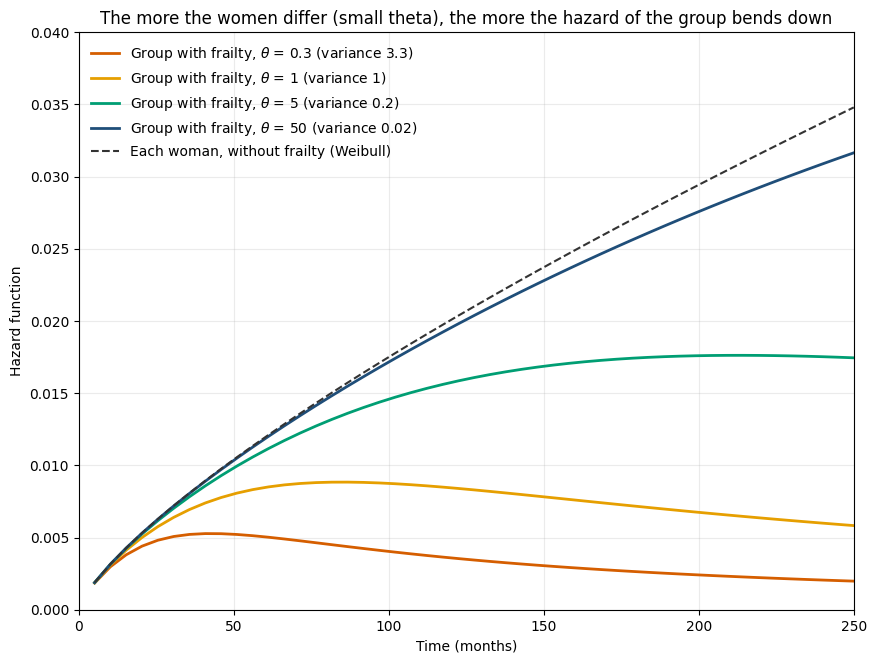

In [16]:
fig, ax = plt.subplots(figsize=(10, 7.5))
for theta, color in zip([0.3, 1, 5, 50], ['#D55E00', opt_color, '#009E73', line_color]):
    PlotFrailtyHazard(ax, theta, color=color)
FormatFrailtyHazard(ax)
ax.set_title('The more the women differ (small theta), the more the hazard of the group bends down')

## Auxiliary functions to calculate:

All of them evaluate a function at every time for each draw of the posterior distribution, and return the posterior mean and the credible interval at each time.

In [17]:
def TimeArray(t_vect):
    return xr.DataArray(t_vect, dims="time", coords={"time": t_vect})

def SummarizeDraws(draws, t_vect):
    # Posterior mean and credible interval, at each time, of the draws of a function
    interval = az.hdi(draws.rename("function"), hdi_prob=1-ALPHA)["function"]

    return pd.DataFrame(
        {
            "mean": draws.mean(("chain", "draw")).to_numpy(),
            "lower": interval.sel(hdi="lower").to_numpy(),
            "upper": interval.sel(hdi="higher").to_numpy()
        },
        index=t_vect
    )

1. Survivor function for each group: $S(t)$.

In [18]:
def CalculateSurvivorFunction(t_vect, trace, group):
    draws = UnconditionalSurvivor(
        TimeArray(t_vect),
        trace.posterior["Theta"],
        trace.posterior["Rho"],
        trace.posterior["Lambda"].isel(group=group)
    )
    return SummarizeDraws(draws, t_vect)

2. Conditional survivor function for each observation given the frailty: $S(t|z)$, z is estimated with the posterior expected value.

In [19]:
def CalculateConditionalSurvivorFunctionGivenFrailty(t_vect, trace, group, data):
    # The data must contain a "Frailty" column with the estimated frailty for each observation
    frailty = xr.DataArray(data["Frailty"].to_numpy(), dims="observation")
    draws = ConditionalSurvivor(
        TimeArray(t_vect),
        frailty,
        trace.posterior["Rho"],
        trace.posterior["Lambda"].isel(group=group)
    )
    AllCondSurvivor = draws.mean(("chain", "draw")).transpose("observation", "time")

    return pd.DataFrame(AllCondSurvivor.to_numpy(), columns=t_vect)

3. Survivor function for each group: $S(t)$, using the estimate $$\widehat{S}(t)=\frac{\sum_{i=1}^n S(t|z_i)f_Z(z_i)}{\sum_{i=1}^n f_Z(z_i)}$$

where $f_Z(z_i)$ is the posterior density of the frailty of the $i$-th woman, evaluated at her estimated frailty and averaged over the draws of the posterior distribution.

In [20]:
def CalculateUnconditionalSurvivorFunctionGivenFrailty(cond_surv, trace, group, data):
    # The data must contain a "Frailty" column with the estimated frailty for each observation

    theta = trace.posterior["Theta"].to_numpy()
    rho = trace.posterior["Rho"].to_numpy()
    lam = trace.posterior["Lambda"].isel(group=group).to_numpy()

    density_frail = []

    for i in data.index:
        _ = data.loc[i]
        density_frail.append(
            PosteriorDensityFrailty(_["Frailty"], _["time"], _["status"], theta, rho, lam).mean()
        )

    density_frail = np.array(density_frail)

    return cond_surv.mul(density_frail, axis=0).sum() / density_frail.sum()

4. Hazard function for each group.

In [21]:
def CalculateHazardFunction(t_vect, trace, group):
    #Unconditional hazard functions
    draws = UnconditionalHazard(
        TimeArray(t_vect),
        trace.posterior["Theta"],
        trace.posterior["Rho"],
        trace.posterior["Lambda"].isel(group=group)
    )
    return SummarizeDraws(draws, t_vect)

5. Observed hazard ratio.

In [22]:
def CalculateHazardRatio(t_vect, trace):
    draws = HazardRatio(
        TimeArray(t_vect),
        trace.posterior["Theta"],
        trace.posterior["Rho"],
        trace.posterior["Lambda"].isel(group=0),
        trace.posterior["Lambda"].isel(group=1)
    )
    return SummarizeDraws(draws, t_vect)

## Auxiliary functions to plot:

In [23]:
def PlotKm(ax, km_estimate, color, label=None, band=True):
    # Kaplan-Meier estimator as a step function, with a tick at each censored time
    surv = km_estimate.survival_function_.iloc[:, 0]
    if band:
        ci = km_estimate.confidence_interval_
        ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=color, alpha=0.25, lw=0)
    ax.step(surv.index, surv, where='post', color=color, lw=2, label=label)
    censored = km_estimate.event_table.index[km_estimate.event_table['censored'] > 0]
    ax.plot(censored, surv.loc[censored], '|', color=color, markersize=11, markeredgewidth=2)

def PlotCurve(ax, curve, color, label=None, band=True):
    # Posterior mean of a function of time, with its credible interval
    if band:
        ax.fill_between(curve.index, curve["lower"], curve["upper"], color=color, alpha=0.25, lw=0)
    ax.plot(curve.index, curve["mean"], color=color, lw=2, label=label)

def FormatSurvivorAxes(ax):
    ax.set_xlabel("Time (months)")
    ax.set_xlim(0, T_VECT[-1])
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.25)

1. Two plots, side by side. The first plot shows the unconditional survivor function for the group, and the KM estimator. The second plot shows the unconditional survivor function for the group and the individual conditional survivor functions.

In [24]:
def PlotUnconditionalAndConditionalSurvivorFunctions(uncond_surv, cond_surv, km_estimate, color, label):
    fig, ax = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

    # First plot
    # Plot the unconditional survivor function and the Kaplan-Meier estimator
    PlotKm(ax[0], km_estimate, color, 'Kaplan-Meier estimator')
    ax[0].plot(uncond_surv.index, uncond_surv['mean'], color=ref_color, lw=2, ls='--', label='Frailty model, whole group')

    # Second plot
    # Plot the conditional survivor functions
    for index in range(len(cond_surv)):
        ax[1].plot(cond_surv.columns, cond_surv.loc[index], color=color, lw=1, alpha=0.6,
                   label='Each woman, given her estimated frailty' if index == 0 else None)

    # Plot the unconditional plot
    ax[1].plot(uncond_surv.index, uncond_surv['mean'], color=ref_color, lw=2, ls='--', label='Frailty model, whole group')

    # General options for the plot
    for a in ax:
        FormatSurvivorAxes(a)
    ax[0].set_ylabel("Survivor function")
    ax[0].legend(loc='lower left', frameon=False)
    ax[1].legend(loc='upper right', frameon=False)
    ax[0].set_title(f"{label}: the group")
    ax[1].set_title(f"{label}: each woman")
    plt.tight_layout()

2. Two plots. The first plot shows the KM estimators for both groups. The second plot shows the unconditional survivor functions for both groups.

In [25]:
def PlotKmAndUnconditionalSideBySide(uncond_surv_0, uncond_surv_1, km_estimate_0, km_estimate_1):

    fig, ax = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

    # First plot
    # Plot the Kaplan-Meier estimators
    PlotKm(ax[0], km_estimate_0, GROUP_COLORS[0], GROUPS[0])
    PlotKm(ax[0], km_estimate_1, GROUP_COLORS[1], GROUPS[1])

    # Second plot
    # Plot the frailty model
    PlotCurve(ax[1], uncond_surv_0, GROUP_COLORS[0], GROUPS[0])
    PlotCurve(ax[1], uncond_surv_1, GROUP_COLORS[1], GROUPS[1])

    # General options for the plot
    for a in ax:
        FormatSurvivorAxes(a)
    ax[0].legend(loc='lower left', frameon=False)
    ax[0].set_ylabel("Survivor function")
    ax[0].set_title(f"Kaplan-Meier estimator\n({(1 - ALPHA) * 100:.0f}% confidence interval, ticks are censored times)")
    ax[1].set_title(f"Weibull-Gamma frailty\n(posterior mean and {interval_label})")
    plt.tight_layout()

3. Similar to the previous one, but in one plot. Confidence interval for the KM estimators are included, but confidence intervals for the frailty model are not included.

In [26]:
def PlotKmAndUnconditionalSamePlot(uncond_surv_0, uncond_surv_1, km_estimate_0, km_estimate_1):

    fig, ax = plt.subplots(figsize=(10, 7.5))

    # Plot the Kaplan-Meier estimators
    PlotKm(ax, km_estimate_0, GROUP_COLORS[0], GROUPS[0])
    PlotKm(ax, km_estimate_1, GROUP_COLORS[1], GROUPS[1])

    # Plot the frailty model
    PlotCurve(ax, uncond_surv_0, GROUP_COLORS[0], band=False)
    PlotCurve(ax, uncond_surv_1, GROUP_COLORS[1], band=False)

    # General options for the plot
    FormatSurvivorAxes(ax)
    ax.legend(loc='lower left', frameon=False)
    ax.set_ylabel("Survivor function")
    ax.set_title("The frailty model follows the Kaplan-Meier estimator of each group\n"
                 "(steps and bands: Kaplan-Meier, curves: frailty model)")

4. Plot the hazard functions for both groups in the same plot.

In [27]:
def PlotHazardSamePlot(hazard_0, hazard_1):

    fig, ax = plt.subplots(figsize=(10, 7.5))

    PlotCurve(ax, hazard_0, GROUP_COLORS[0], GROUPS[0])
    PlotCurve(ax, hazard_1, GROUP_COLORS[1], GROUPS[1])

    # General options for the plot
    ax.legend(loc='upper right', frameon=False)
    ax.set_xlabel("Time (months)")
    ax.set_ylabel("Hazard function (deaths per woman per month)")
    ax.set_xlim(0, T_VECT[-1])
    ax.set_ylim(0, None)
    ax.set_title(f"Hazard function of each group\n(posterior mean and {interval_label})")
    ax.grid(True, alpha=0.25)

5. Plot the hazard ratio.

In [28]:
def PlotHazardRatio(hazard_ratio):

    fig, ax = plt.subplots(figsize=(10, 7.5))

    ax.fill_between(hazard_ratio.index, hazard_ratio["lower"], hazard_ratio["upper"], color=GROUP_COLORS[0], alpha=0.25, lw=0,
                    label=interval_label)
    ax.plot(hazard_ratio.index, hazard_ratio["mean"], color=line_color, lw=2, label='Posterior mean')

    ax.axhline(1, linestyle="--", color=ref_color, lw=1, label='Equal hazards')

    ax.set_xlabel("Time (months)")
    ax.set_ylabel("Hazard ratio (positive against negative staining)")
    ax.set_xlim(hazard_ratio.index[0], T_VECT[-1])
    ax.set_ylim(0, None)
    ax.set_title("With frailty the hazard ratio is not constant: it decreases with time")
    ax.legend(loc='upper right', frameon=False)
    ax.grid(True, alpha=0.25)

6. Histogram of the posterior draws of a quantity, with the median and the credible interval.

In [29]:
def PlotPosterior(ax, draws, limits, color, alpha=0.55):
    # The posterior distributions have long tails, we show the central part
    draws = np.asarray(draws).ravel()
    median = np.median(draws)
    low, upp = az.hdi(draws, hdi_prob=1-ALPHA)
    ax.hist(draws, bins=np.linspace(limits[0], limits[1], 61), density=True, color=color, alpha=alpha, edgecolor='white',
            linewidth=0.5, label='Posterior draws')
    ax.axvline(median, color=ref_color, lw=2, label='Posterior median')
    ax.plot([low, min(upp, limits[1])], [0, 0], color=ref_color, lw=7, solid_capstyle='butt', clip_on=False, zorder=5,
            label=interval_label)
    ax.set_xlim(limits)
    ax.set_yticks([])
    ax.grid(True, axis='x', alpha=0.25)
    return median, low, upp

## Fit the Weibull AFT with Gamma Frailty model, using Bayesian approach

$$
\begin{align*}
T|\lambda,\rho,\text{Frailty} &\sim \textsf{Weibull}(\lambda,\rho)\ \text{with the hazard multiplied by the frailty} \\
\lambda_{[j]} &= \exp\{\beta_{[j]}\},\quad j=0,1 \\
\beta_{[j]} &\sim \textsf{Normal}(0,10^2) \\
\rho &\sim \textsf{HalfNormal}(10) \\
\text{Frailty}|\theta &\sim \textsf{Gamma}(\theta, \theta) \\
\theta &\sim \textsf{Exponential}(1)
\end{align*}
$$

The frailties are integrated out: the likelihood of point 11 only has the parameters $\theta$, $\rho$ and $\beta$. The expected frailty of each woman is then computed from them (point 5).

In [30]:
y = DatOriginal["time"].values
ev = DatOriginal["status"].values
stain = DatOriginal["stain"].values

with pm.Model(coords={"group": GROUPS, "observation": DatOriginal.index}) as WeibullFrailtyRegression:
    # Frailty parameter
    Theta = pm.Exponential("Theta", 1)

    # Regression
    Beta = pm.Normal("Beta", mu=0, sigma=10, dims="group")

    # Weibull parameters
    Rho = pm.HalfNormal("Rho", sigma=10)
    Lambda = pm.Deterministic("Lambda", np.exp(Beta), dims="group")

    # Time quantile
    MedianTime = pm.Deterministic("MedianTime", TimeQuantile(0.5, Theta, Rho, Lambda), dims="group")

    # Expected frailties
    if FRAILTY:
        Frailty = pm.Deterministic("Frailty", ExpectedFrailty(y, ev, Theta, Rho, Lambda[stain]), dims="observation")

    # Log-likelihood
    pm.Potential(
        "Loglikelihood", LogLikelihood(y, ev, Theta, Rho, Lambda[stain])
    )

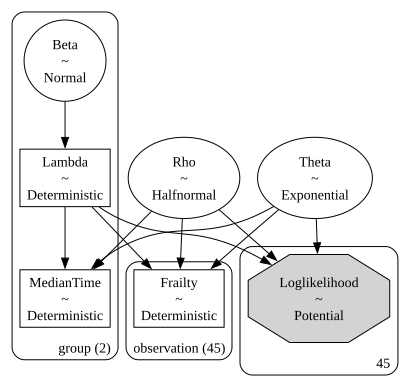

In [31]:
pm.model_to_graphviz(WeibullFrailtyRegression)

In [32]:
with WeibullFrailtyRegression:
    TraceWeibull = pm.sample(target_accept=0.95, random_seed=SEED)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [Theta, Beta, Rho]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 33 seconds.


## Results of the model

In [33]:
Summary = az.summary(
    TraceWeibull,
    var_names=["Theta", "Rho", "Beta", "Lambda", "MedianTime"],
    kind="stats",
    stat_focus="median",
    hdi_prob=1-ALPHA
)

Summary

,median,mad,eti_2.5%,eti_97.5%
Theta,0.348,0.161,0.067,2.023
Rho,1.720,0.407,0.939,4.686
Beta[Stain Negative],4.993,0.430,3.643,6.233
Beta[Stain Positive],3.797,0.343,2.626,4.733
Lambda[Stain Negative],147.419,61.065,38.221,509.247
Lambda[Stain Positive],44.585,14.983,13.815,113.613
MedianTime[Stain Negative],241.885,77.816,96.717,725.535
MedianTime[Stain Positive],73.216,15.402,40.703,151.957


Estimate the frailty for each observation

In [34]:
if FRAILTY:
    SummaryFrail = az.summary(
        TraceWeibull,
        var_names="Frailty",
        kind="stats",
        stat_focus="median",
        hdi_prob=1-ALPHA
    )

Add the estimated frailty to each observation

In [35]:
if FRAILTY:
    Frailties = SummaryFrail[SummaryFrail.index.str.startswith("Frailty")]["median"]
    DatOriginal.loc[:,"Frailty"] = Frailties.values

The estimated frailty of each woman against her time. A woman who died early is estimated as frail (above 1); one who was still alive after a long time, as robust (below 1). The longer a woman is observed, the more is known about her frailty.

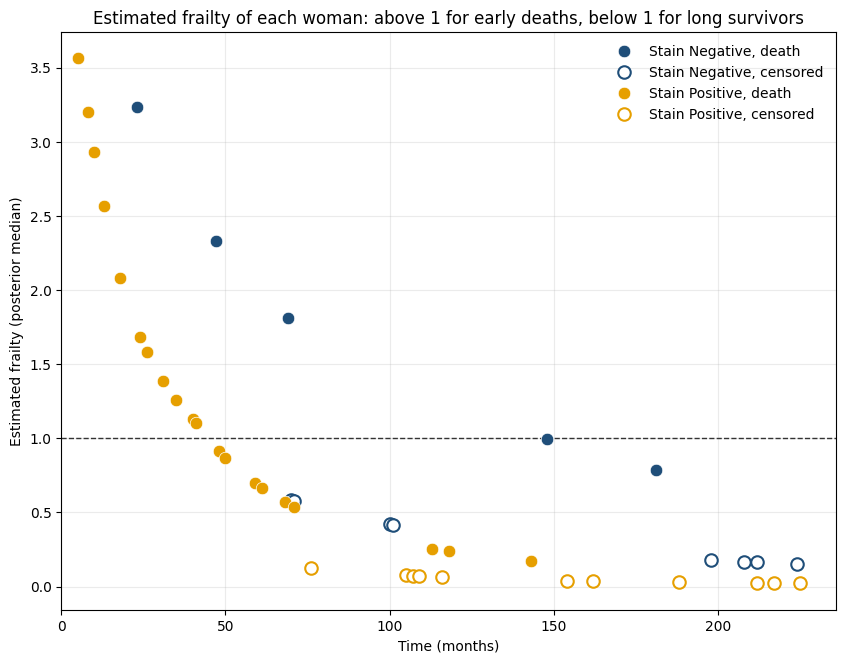

In [36]:
if FRAILTY:
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.axhline(1, color=ref_color, lw=1, ls='--')
    for g in range(2):
        DatGroup = DatOriginal[DatOriginal['stain'] == g]
        Death = DatGroup['status'] == 1
        ax.plot(DatGroup.loc[Death, 'time'], DatGroup.loc[Death, 'Frailty'], 'o', color=GROUP_COLORS[g], markersize=9,
                markeredgecolor='white', markeredgewidth=0.5, label=f'{GROUPS[g]}, death')
        ax.plot(DatGroup.loc[~Death, 'time'], DatGroup.loc[~Death, 'Frailty'], 'o', markerfacecolor='white', markersize=9,
                markeredgecolor=GROUP_COLORS[g], markeredgewidth=1.5, label=f'{GROUPS[g]}, censored')

    ax.set_xlabel('Time (months)')
    ax.set_ylabel('Estimated frailty (posterior median)')
    ax.set_xlim(0, None)
    ax.set_title('Estimated frailty of each woman: above 1 for early deaths, below 1 for long survivors')
    ax.legend(loc='upper right', frameon=False)
    ax.grid(True, alpha=0.25)

## Calculate statistics of interests

In [37]:
DatOriginalNegative = DatOriginal[DatOriginal['stain']==0]
DatOriginalPositive = DatOriginal[DatOriginal['stain']==1]

In [38]:
# Kaplan-Meier estimators for the stain negative and positive
KmNegative = KaplanMeierFitter(alpha=ALPHA)
KmNegative.fit(DatOriginalNegative['time'], event_observed=DatOriginalNegative['status'])

KmPositive = KaplanMeierFitter(alpha=ALPHA)
KmPositive.fit(DatOriginalPositive['time'], event_observed=DatOriginalPositive['status'])

# Survivor function estimators for the stain negative and positive
SurvivorNegative = CalculateSurvivorFunction(T_VECT, TraceWeibull, 0)
SurvivorPositive = CalculateSurvivorFunction(T_VECT, TraceWeibull, 1)

# Hazard function estimators for the stain negative and positive
# (the hazard functions are not evaluated at zero, where they are zero or infinite)
HazardNegative = CalculateHazardFunction(T_VECT[1:], TraceWeibull, 0)
HazardPositive = CalculateHazardFunction(T_VECT[1:], TraceWeibull, 1)

# Hazard ratio
HazardRatioTable =  CalculateHazardRatio(T_VECT[1:], TraceWeibull)

# Conditional survivor function for each observation, given its frailty level
if FRAILTY:
    ConditionalSurvivorNegative = CalculateConditionalSurvivorFunctionGivenFrailty(T_VECT, TraceWeibull, 0, DatOriginalNegative)
    ConditionalSurvivorPositive = CalculateConditionalSurvivorFunctionGivenFrailty(T_VECT, TraceWeibull, 1, DatOriginalPositive)

    ApproximateSurvivorNegative = CalculateUnconditionalSurvivorFunctionGivenFrailty(
        ConditionalSurvivorNegative, TraceWeibull, 0, DatOriginalNegative)
    ApproximateSurvivorPositive = CalculateUnconditionalSurvivorFunctionGivenFrailty(
        ConditionalSurvivorPositive, TraceWeibull, 1, DatOriginalPositive)

## Plotting statistics of interests

Plot KM with unconditional survivor functions VS unconditional survivor functions and conditional survivor functions.

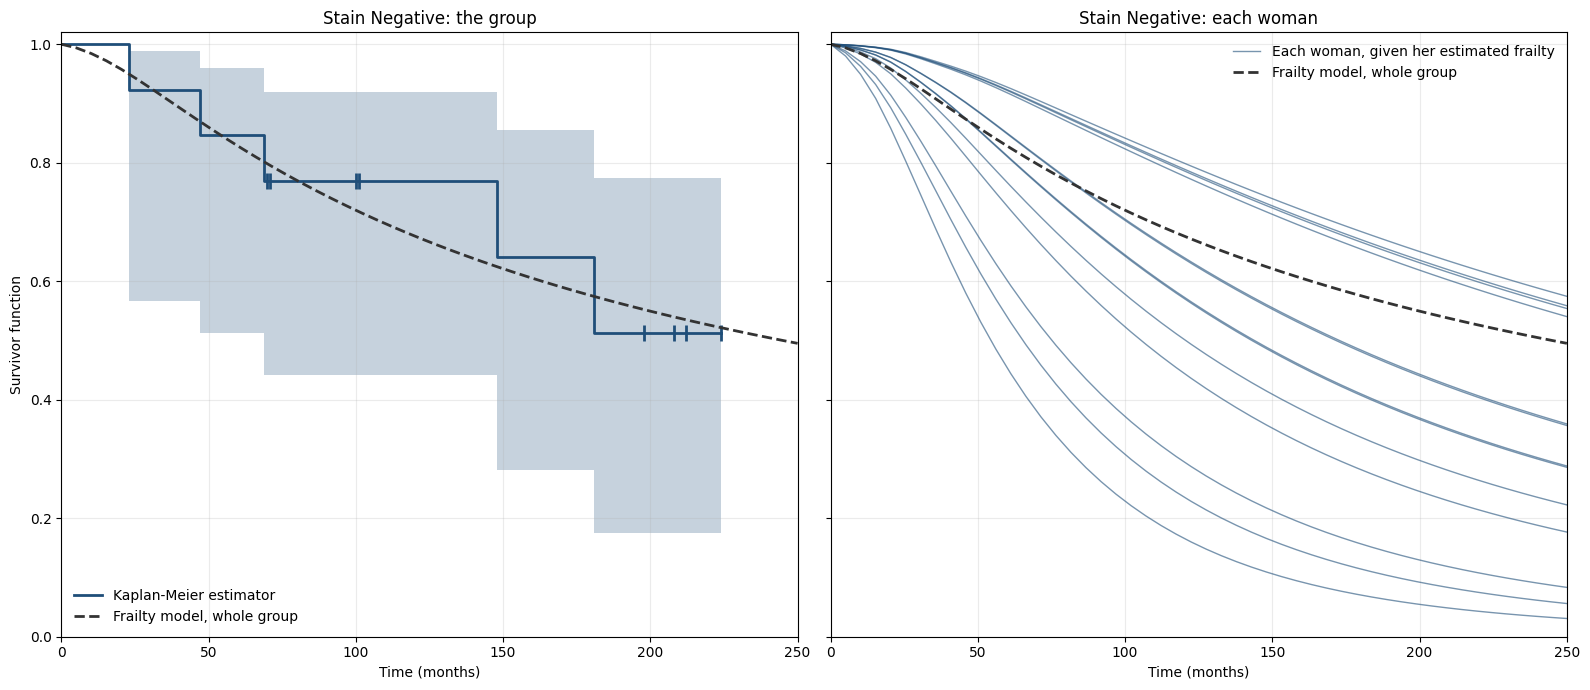

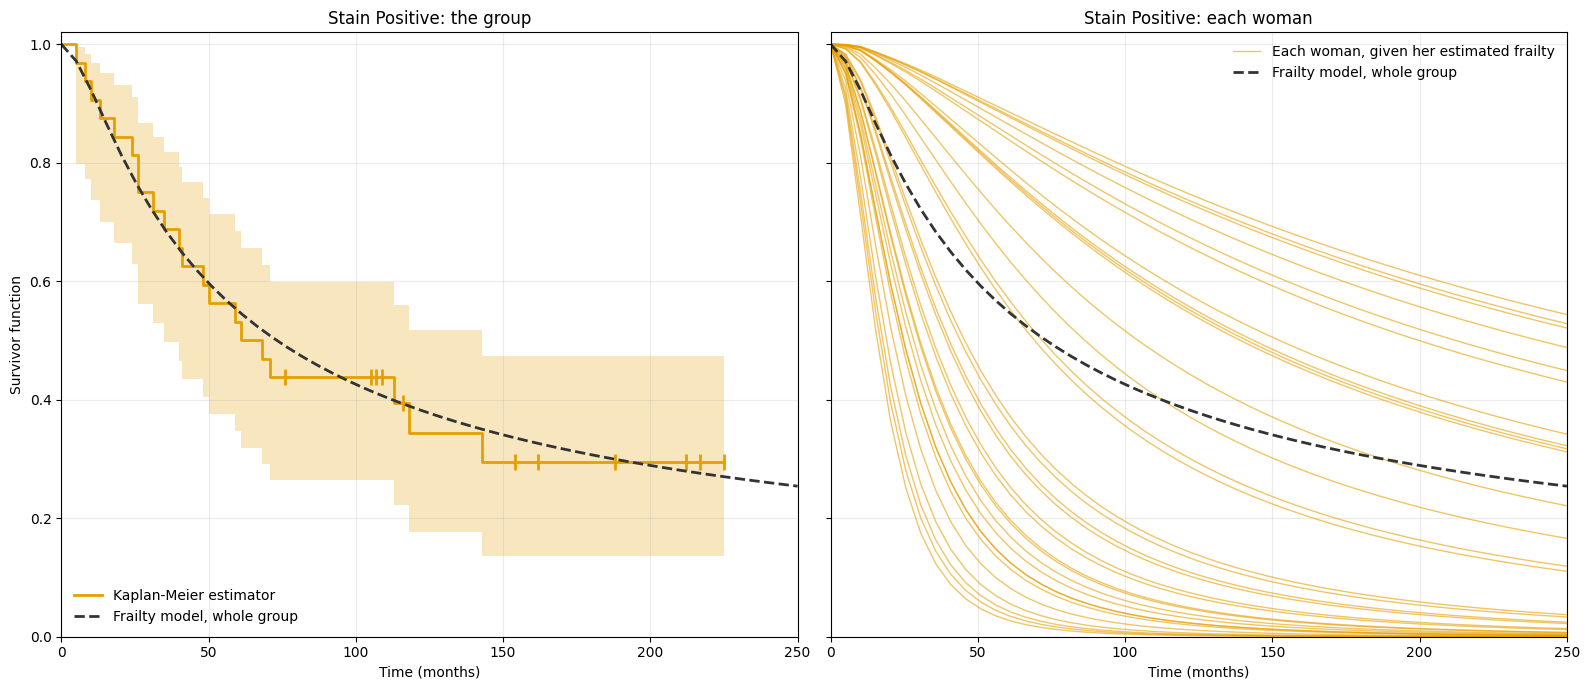

In [39]:
if FRAILTY:
    PlotUnconditionalAndConditionalSurvivorFunctions(
        SurvivorNegative, ConditionalSurvivorNegative, KmNegative, GROUP_COLORS[0], GROUPS[0]
    )

    PlotUnconditionalAndConditionalSurvivorFunctions(
        SurvivorPositive, ConditionalSurvivorPositive, KmPositive, GROUP_COLORS[1], GROUPS[1]
    )

Plot the survivor function of each group obtained in two ways: with the formula of point 7, and as the weighted average of the survivor functions of its women (point 3 of the auxiliary functions).

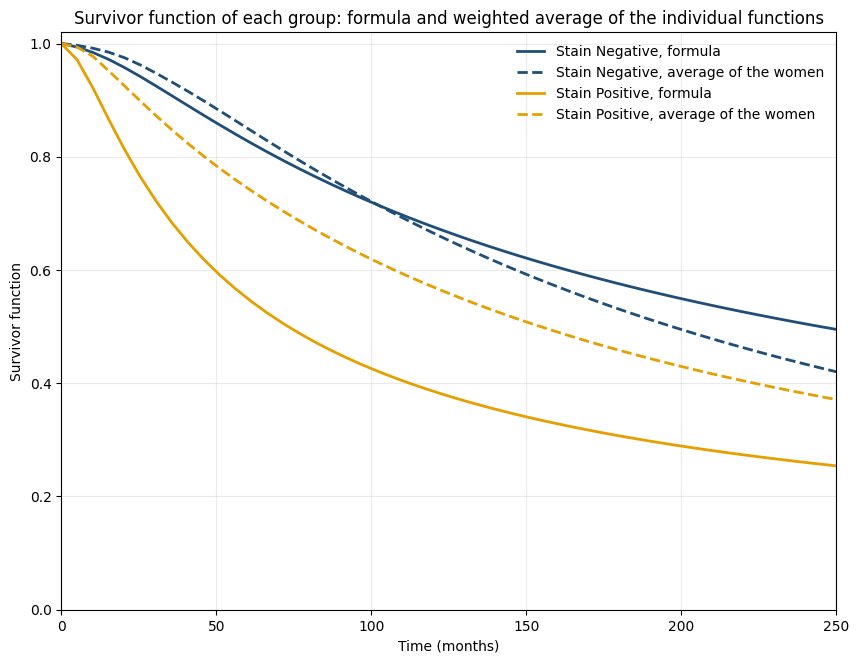

In [40]:
if FRAILTY:
    fig, ax = plt.subplots(figsize=(10, 7.5))
    for g, (formula, approximate) in enumerate([(SurvivorNegative, ApproximateSurvivorNegative),
                                                (SurvivorPositive, ApproximateSurvivorPositive)]):
        ax.plot(formula.index, formula["mean"], color=GROUP_COLORS[g], lw=2, label=f"{GROUPS[g]}, formula")
        ax.plot(approximate.index, approximate, color=GROUP_COLORS[g], lw=2, ls="--",
                label=f"{GROUPS[g]}, average of the women")
    FormatSurvivorAxes(ax)
    ax.set_ylabel("Survivor function")
    ax.set_title("Survivor function of each group: formula and weighted average of the individual functions")
    ax.legend(loc="upper right", frameon=False)

The two estimates do not coincide, mainly in the positive group. The weights are the posterior densities of the frailties, which are largest for the women observed for a long time: their frailty is small and known with more precision. Those are the women with the highest survivor functions, so the weighted average is above the formula.

Plot KM VS unconditional survivor functions.

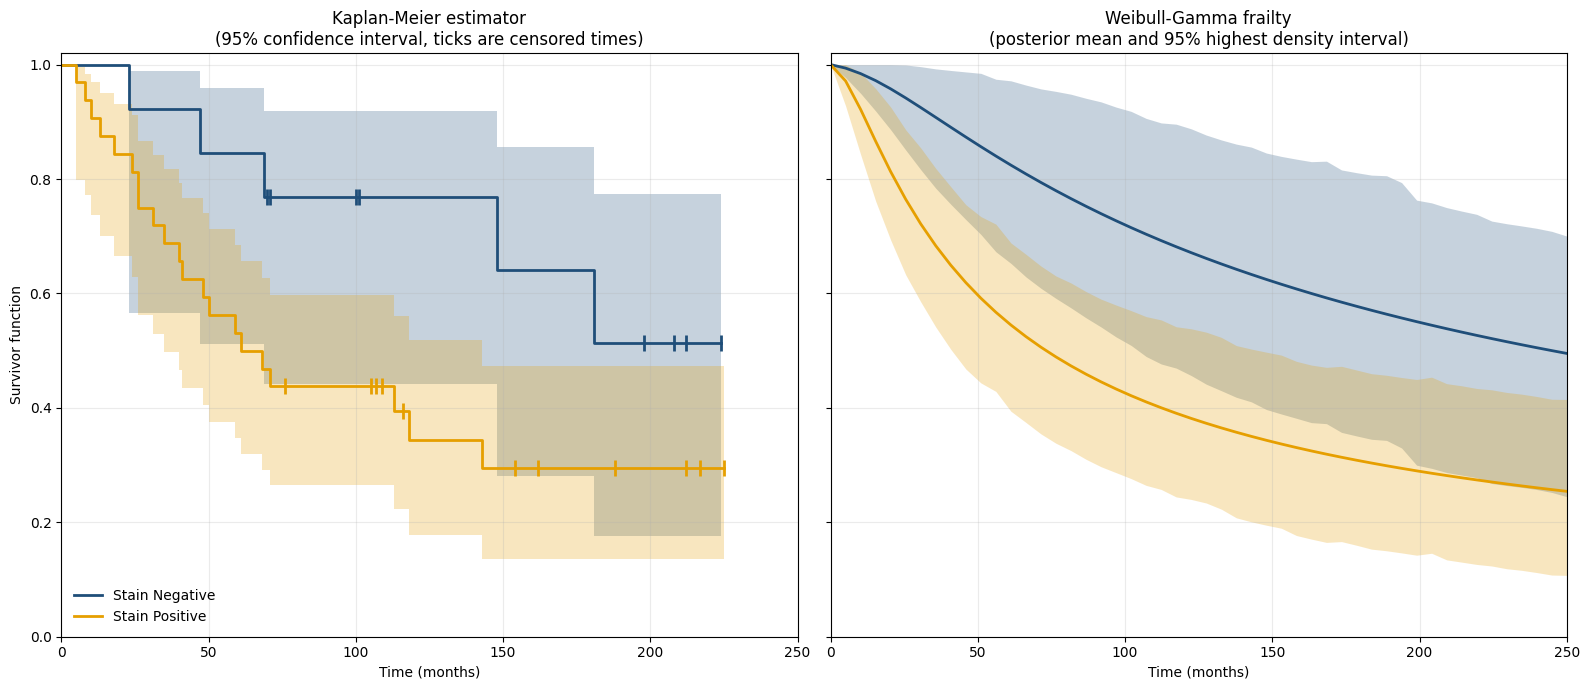

In [41]:
PlotKmAndUnconditionalSideBySide(SurvivorNegative, SurvivorPositive, KmNegative, KmPositive)

Plot KM and unconditional survivor functions.

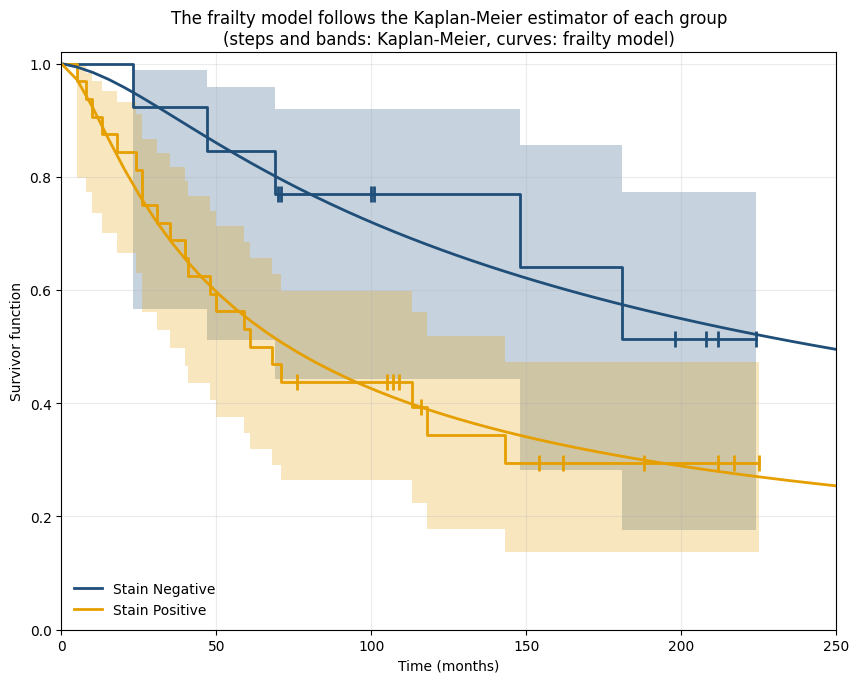

In [42]:
PlotKmAndUnconditionalSamePlot(SurvivorNegative, SurvivorPositive, KmNegative, KmPositive)

Plot hazard functions

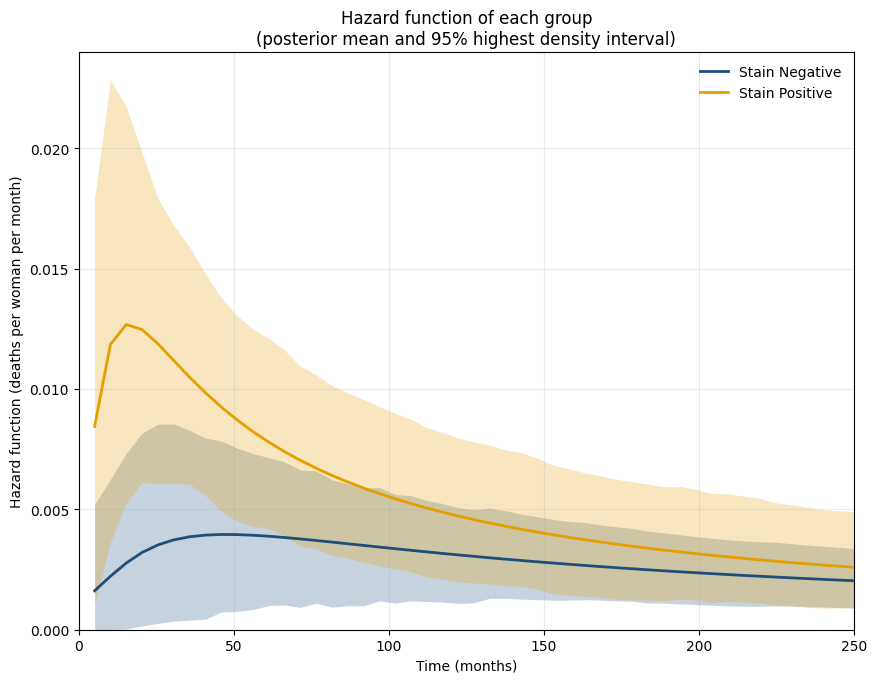

In [43]:
PlotHazardSamePlot(HazardNegative, HazardPositive)

Plot hazard ratio

Only from 100 months on. At early times a few draws of the posterior distribution give enormous hazard ratios, and the posterior mean is not a useful summary there.

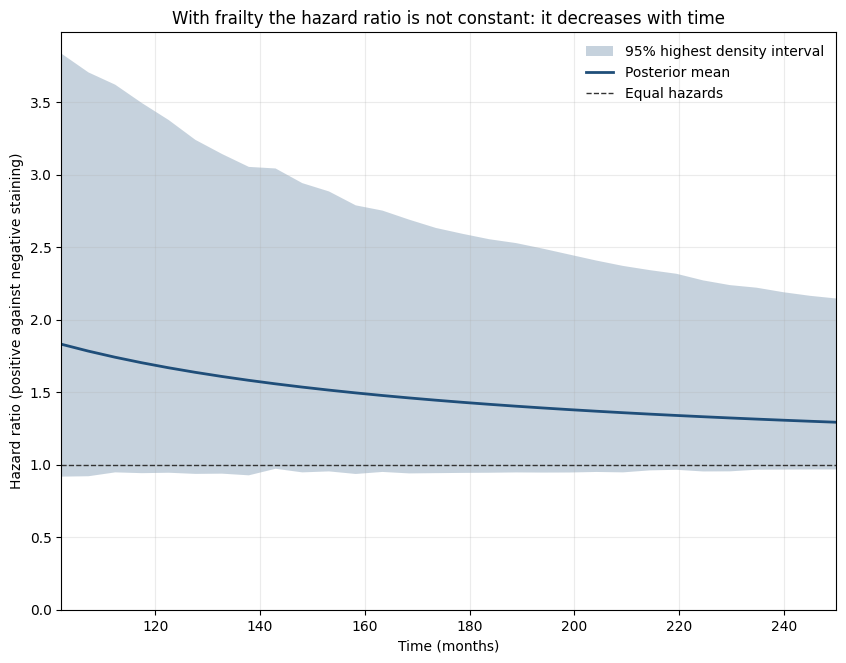

In [44]:
PlotHazardRatio(HazardRatioTable.iloc[19:])

Plot median survival times

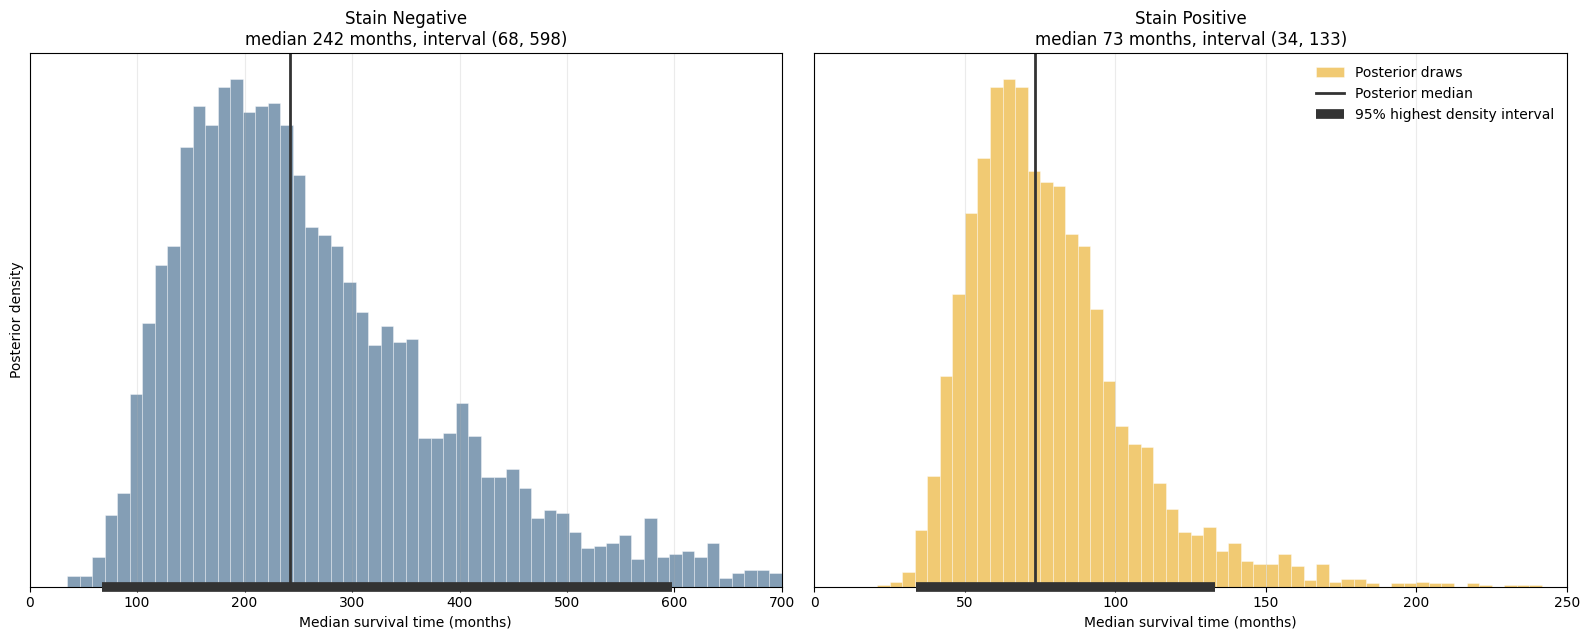

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for g, (ax, limits) in enumerate(zip(axes, [(0, 700), (0, 250)])):
    median, low, upp = PlotPosterior(ax, TraceWeibull.posterior["MedianTime"].isel(group=g), limits, GROUP_COLORS[g])
    ax.set_xlabel('Median survival time (months)')
    ax.set_title(f'{GROUPS[g]}\nmedian {median:.0f} months, interval ({low:.0f}, {upp:.0f})')
axes[0].set_ylabel('Posterior density')
axes[1].legend(loc='upper right', frameon=False)
plt.tight_layout()

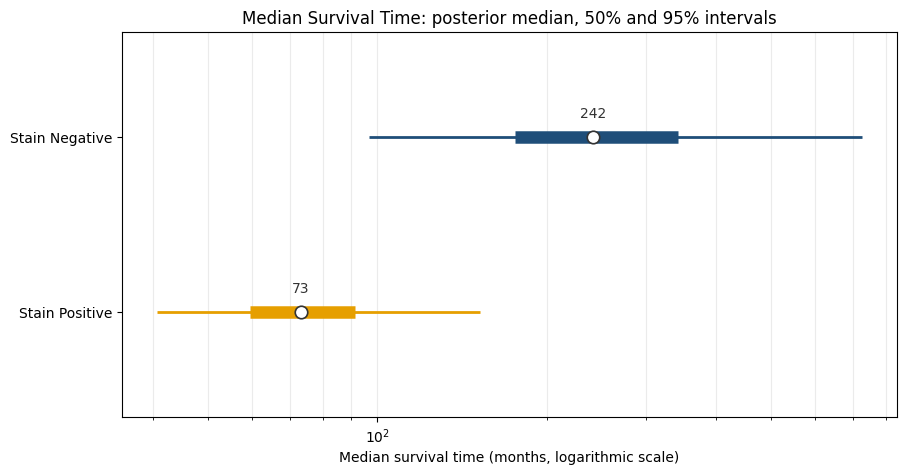

In [46]:
fig, ax = plt.subplots(figsize=(10, 5))
for g in range(2):
    draws = TraceWeibull.posterior["MedianTime"].isel(group=g).to_numpy().ravel()
    q = np.quantile(draws, [ALPHA/2, 0.25, 0.5, 0.75, 1-ALPHA/2])
    ax.plot([q[0], q[4]], [g, g], color=GROUP_COLORS[g], lw=2, solid_capstyle='butt')
    ax.plot([q[1], q[3]], [g, g], color=GROUP_COLORS[g], lw=9, solid_capstyle='butt')
    ax.plot(q[2], g, 'o', color='white', markersize=9, markeredgecolor=ref_color, markeredgewidth=1.2, zorder=5)
    ax.annotate(f'{q[2]:.0f}', (q[2], g), xytext=(0, 14), textcoords='offset points', ha='center', color=ref_color)

ax.set_xscale('log')
ax.set_yticks([0, 1], GROUPS)
ax.set_ylim(-0.6, 1.6)
ax.invert_yaxis()
ax.set_xlabel('Median survival time (months, logarithmic scale)')
ax.set_title(f'Median Survival Time: posterior median, 50% and {(1 - ALPHA) * 100:.0f}% intervals')
ax.grid(True, axis='x', which='both', alpha=0.25)